# 🎵 Spotify AI DJ Agent — Traducción completa de n8n a LangChain (Google Colab)

Este notebook implementa la arquitectura completa del flujo **`Spotify_Agent`** originalmente diseñado en n8n, traducida a **Python + LangChain** manteniendo paridad funcional total:

| Módulo en n8n | Equivalente en este Notebook (LangChain) |
| :--- | :--- |
| `Telegram Trigger` + `Switch` (Texto / Audio) | `pyTelegramBotAPI` (`telebot`) con handlers separados para `text` y `voice`/`audio` |
| `Get a file Audio` + `Analyze audio` (Gemini) | Descarga de archivo desde Telegram + `google-genai` (`gemini-3.1-flash-lite`) |
| `Edit Fields Tex` / `Edit Fields Aud` (`chatInput`) | Normalización unificada a `chat_input` |
| `OpenAI Chat Model` (`gpt-5-mini`) | `ChatOpenAI` (`langchain_openai`) |
| `Simple Memory` (`window = 50`, key `"memory"`) | Historial de ventana deslizante (`WindowedChatMessageHistory`, últimos 50 mensajes) |
| `Spotify Search / Play / Queue / Play Playlist` | 4 herramientas `@tool` autenticadas con Spotify OAuth2 (`spotipy` + `requests`) |
| `Wikipedia` | `WikipediaQueryRun` (`langchain_community`) |
| `Supabase Vector Store1` (`spotify` / `match_spotify`) | Herramienta RAG `@tool` usando `OpenAIEmbeddings` (1536 dims) + RPC `match_spotify` |
| `Download file` + `Supabase Vector Store` (Insert) | Celda opcional de ingesta PDF (`PyPDFLoader` + `RecursiveCharacterTextSplitter`) |
| `FuzzyMusicAdvisor` (Code Tool JS) | Herramienta `@tool` en Python con funciones triangulares y defuzzificación Sugeno |
| `AI Agent` + `Send a text message` | `create_tool_calling_agent` + `AgentExecutor` + respuesta directa a Telegram |

## 1. Instalación de dependencias

In [ ]:
!pip install -q \
    "langchain>=0.3.15,<0.4.0" \
    "langchain-openai>=0.3.0,<0.4.0" \
    "langchain-community>=0.3.15,<0.4.0" \
    "langchain-core>=0.3.30,<0.4.0" \
    "google-genai>=1.0.0" \
    "spotipy>=2.24.0" \
    "supabase>=2.10.0" \
    "pyTelegramBotAPI>=4.23.0" \
    "wikipedia>=1.4.0" \
    "pypdf>=5.0.0" \
    "matplotlib>=3.8.0" \
    "numpy>=1.26.0"

print("✅ Dependencias instaladas correctamente.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
langgraph-prebuilt 1.1.1 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
langgraph 1.2.19 requires langchain-core<2,>=1.4.7, but you have langchain-core 0.3.86 which is incompatible.
langgraph-sdk 0.4.12 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
✅ Dependencias instaladas correctamente.


## 2. Configuración de credenciales y variables de entorno

* **`SPOTIFY_DEVICE_ID`** *(Opcional)*: Se deja vacío (`""`) para usar el reproductor activo, o pegar el ID del PC/celular para forzar la reproducción en ese dispositivo.

In [ ]:
import os

def get_secret(key: str, default: str = "") -> str:
    """Intenta leer el secreto desde Colab Secrets; si no existe, usa el valor por defecto."""
    try:
        from google.colab import userdata
        val = userdata.get(key)
        if val:
            return val
    except Exception:
        pass
    return os.environ.get(key, default)

OPENAI_API_KEY       = get_secret("OPENAI_API_KEY", "sk-TU_OPENAI_API_KEY")
GEMINI_API_KEY       = get_secret("GEMINI_API_KEY", "TU_GEMINI_API_KEY")
TELEGRAM_BOT_TOKEN   = get_secret("TELEGRAM_BOT_TOKEN", "TU_TELEGRAM_BOT_TOKEN")

SUPABASE_URL         = get_secret("SUPABASE_URL", "https://TU_PROYECTO.supabase.co")
SUPABASE_KEY         = get_secret("SUPABASE_KEY", "TU_SUPABASE_ANON_O_SERVICE_ROLE_KEY")

SPOTIFY_CLIENT_ID     = get_secret("SPOTIFY_CLIENT_ID", "TU_SPOTIFY_CLIENT_ID")
SPOTIFY_CLIENT_SECRET = get_secret("SPOTIFY_CLIENT_SECRET", "TU_SPOTIFY_CLIENT_SECRET")
SPOTIFY_REDIRECT_URI  = get_secret("SPOTIFY_REDIRECT_URI", "https://oauth.n8n.cloud/oauth2/callback")
SPOTIFY_DEVICE_ID     = get_secret("SPOTIFY_DEVICE_ID", "")  # Opcional: ID fijo de tu PC o celular

# Modelos del flujo n8n
OPENAI_CHAT_MODEL      = "gpt-5-mini"
OPENAI_EMBEDDING_MODEL = "text-embedding-3-small"
GEMINI_AUDIO_MODEL     = "gemini-3.1-flash-lite"

# Exportar variables para LangChain
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

print("✅ Configuración cargada.")

✅ Configuración cargada.


## 3. Autenticación OAuth2 con Spotify (Compatible con Google Colab)

Como Google Colab corre en la nube, no puede abrir un navegador local automáticamente. Esta celda realiza el flujo estándar **Authorization Code** de forma interactiva:
1. Ejecutar la celda y hacer clic en el **enlace de autorización** que se imprime.
2. Aceptar los permisos en Spotify.
3. Spotify redirigirá al Redirect URI (ej. `https://oauth.n8n.cloud/oauth2/callback?code=AQD...`). **Copiar toda la URL de la barra de direcciones del navegador** y pegarla en el cuadro de texto de Colab.
4. El token queda guardado en `.spotify_cache` y se renueva automáticamente.

In [ ]:
import requests
from spotipy.oauth2 import SpotifyOAuth

SPOTIFY_SCOPE = "user-modify-playback-state user-read-playback-state"

sp_oauth = SpotifyOAuth(
    client_id=SPOTIFY_CLIENT_ID,
    client_secret=SPOTIFY_CLIENT_SECRET,
    redirect_uri=SPOTIFY_REDIRECT_URI,
    scope=SPOTIFY_SCOPE,
    cache_path=".spotify_cache",
    open_browser=False,
)

token_info = sp_oauth.get_cached_token()

if not token_info:
    auth_url = sp_oauth.get_authorize_url()
    print("🔗 1. Abre este enlace en tu navegador y autoriza la aplicación:")
    print(auth_url)
    print()
    redirect_response = input("📋 2. Pega aquí la URL completa a la que te redirigió Spotify: ").strip()
    code = sp_oauth.parse_response_code(redirect_response)
    token_info = sp_oauth.get_access_token(code, as_dict=True)

def get_spotify_headers() -> dict:
    """Obtiene un Access Token vigente (refrescándolo automáticamente si expiró)."""
    token = sp_oauth.get_cached_token()
    if not token:
        raise RuntimeError("No hay sesión de Spotify activa. Ejecuta nuevamente la celda de autenticación.")
    return {
        "Authorization": f"Bearer {token['access_token']}",
        "Content-Type": "application/json",
    }

# Verificación rápida y listado de dispositivos disponibles
resp = requests.get("https://api.spotify.com/v1/me/player/devices", headers=get_spotify_headers(), timeout=15)
if resp.status_code == 200:
    devices = resp.json().get("devices", [])
    print("✅ Spotify conectado correctamente.")
    if devices:
        print("📱 Dispositivos detectados:")
        for d in devices:
            estado = "ACTIVO" if d.get("is_active") else "inactivo"
            print(f"   - {d.get('name')} ({d.get('type')}) | {estado} | id: {d.get('id')}")
    else:
        print("⚠️ No hay dispositivos activos detectados. Abre Spotify Web Player o la app de escritorio antes de reproducir.")
else:
    print(f"❌ Error verificando Spotify ({resp.status_code}): {resp.text}")

🔗 1. Abre este enlace en tu navegador y autoriza la aplicación:
https://accounts.spotify.com/authorize?client_id=**************************************************************

📋 2. Pega aquí la URL completa a la que te redirigió Spotify: https://oauth.n8n.cloud/oauth2/callback?code=**********************************************************


/tmp/ipykernel_822/2717603210.py:24: DeprecationWarning: You're using 'as_dict = True'.get_access_token will return the token string directly in future versions. Please adjust your code accordingly, or use get_cached_token instead.
  token_info = sp_oauth.get_access_token(code, as_dict=True)


✅ Spotify conectado correctamente.
📱 Dispositivos detectados:
   - Web Player (Chrome) (Computer) | ACTIVO | id: *****************************************************
   - DESKTOP-M91RDN1 (Computer) | inactivo | id: *******************************************************


## 4. Conexión a Supabase Vector Store (RAG) e Ingesta opcional

Conecta a la tabla **`spotify`** y a la función RPC **`match_spotify`** (vectores de dimensión **1536** generados con `OpenAIEmbeddings`).

* La **celda 4.1** inicializa el cliente de Supabase y el modelo de embeddings.
* La **celda 4.2 (Opcional)** replica el flujo de n8n (`When clicking 'Execute workflow'` → `Download file` → `Default Data Loader` → `Embeddings OpenAI` → `Supabase Vector Store` insert). Correr si se desea volver a cargar `Hot 100.pdf` desde cero.

In [ ]:
from supabase import create_client, Client
from langchain_openai import OpenAIEmbeddings

supabase_client: Client = create_client(SUPABASE_URL, SUPABASE_KEY)
embeddings_model = OpenAIEmbeddings(
    model=OPENAI_EMBEDDING_MODEL,
    dimensions=1536,
    openai_api_key=OPENAI_API_KEY,
)

# Comprobar conteo de documentos en la tabla 'spotify'
try:
    check = supabase_client.table("spotify").select("id", count="exact").limit(1).execute()
    print(f"✅ Conectado a Supabase. Registros en tabla 'spotify': {check.count}")
except Exception as e:
    print(f"⚠️ Error consultando tabla 'spotify' en Supabase: {e}")

✅ Conectado a Supabase. Registros en tabla 'spotify': 14


In [ ]:
# ==========================================================================================
# CELDA OPCIONAL (Equivalente a la rama de ingesta de 'Hot 100.pdf')
# Cambiar EJECUTAR_INGESTA = True solo si se necesita volver a indexar el PDF en Supabase.
# ==========================================================================================
EJECUTAR_INGESTA = False
RUTA_PDF_LOCAL = "/content/Hot 100.pdf"  # Subir el archivo a Colab o montarlo desde Drive

if EJECUTAR_INGESTA:
    from langchain_community.document_loaders import PyPDFLoader
    from langchain.text_splitter import RecursiveCharacterTextSplitter

    print(f"📄 Cargando {RUTA_PDF_LOCAL}...")
    loader = PyPDFLoader(RUTA_PDF_LOCAL)
    docs = loader.load()

    splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
    chunks = splitter.split_documents(docs)
    print(f"✂️ Generados {len(chunks)} fragmentos. Calculando embeddings (1536 dims)...")

    texts = [c.page_content for c in chunks]
    vectors = embeddings_model.embed_documents(texts)

    rows = [
        {
            "content": chunk.page_content,
            "metadata": chunk.metadata,
            "embedding": vector,
        }
        for chunk, vector in zip(chunks, vectors)
    ]

    # Insertar en lotes en la tabla 'spotify'
    batch_size = 50
    for i in range(0, len(rows), batch_size):
        supabase_client.table("spotify").insert(rows[i : i + batch_size]).execute()

    print(f"✅ Ingesta completada: {len(rows)} vectores guardados en la tabla 'spotify'.")
else:
    print("ℹ️ Ingesta omitida (usando los vectores ya existentes en la tabla 'spotify' de Supabase).")

ℹ️ Ingesta omitida (usando los vectores ya existentes en la tabla 'spotify' de Supabase).


## 5. Definición de Herramientas (`@tool`) de LangChain

**Herramientas** conectadas al `AI Agent` en n8n:
1. **`Spotify_Search_Tool`** (`GET /v1/search`, `limit=1`)
2. **`Spotify_Play_Tool`** (`PUT /v1/me/player/play` con `uris`)
3. **`Spotify_Queue_Tool`** (`POST /v1/me/player/queue` con `uri`)
4. **`Spotify_Play_Playlist_Tool`** (`PUT /v1/me/player/play` con `context_uri`)
5. **`Wikipedia`** (`WikipediaQueryRun`)
6. **`Supabase_Vector_Store1`** (Búsqueda vectorial sobre la tabla `spotify` vía RPC `match_spotify`)
7. **`FuzzyMusicAdvisor`** (Motor de inferencia de Lógica Difusa con funciones triangulares y defuzzificación Sugeno)

In [ ]:
import json
from typing import Optional
from pydantic import BaseModel, Field
from langchain_core.tools import tool
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper


def _resolve_device_id() -> Optional[str]:
    """Usa SPOTIFY_DEVICE_ID si fue configurado; si no, intenta detectar un dispositivo disponible si no hay uno activo."""
    if SPOTIFY_DEVICE_ID:
        return SPOTIFY_DEVICE_ID
    try:
        r = requests.get("https://api.spotify.com/v1/me/player/devices", headers=get_spotify_headers(), timeout=10)
        if r.status_code == 200:
            devices = r.json().get("devices", [])
            for d in devices:
                if d.get("is_active"):
                    return d.get("id")
            if devices:
                return devices[0].get("id")
    except Exception:
        pass
    return None


# ------------------------------------------------------------------
# 1. Spotify Search Tool
# ------------------------------------------------------------------
class SpotifySearchInput(BaseModel):
    q: str = Field(description="Nombre de la canción y artista a buscar.")
    type: str = Field(
        default="track",
        description="Tipo de búsqueda: 'track' para canciones sueltas o 'playlist' para listas de reproducción.",
    )

@tool("Spotify_Search_Tool", args_schema=SpotifySearchInput)
def spotify_search_tool(q: str, type: str = "track") -> str:
    """Busca una canción o playlist en Spotify. Recibe el nombre del tema/artista y el tipo ('track' o 'playlist'), y devuelve información incluyendo su 'uri'."""
    search_type = type if type in ("track", "playlist") else "track"
    resp = requests.get(
        "https://api.spotify.com/v1/search",
        headers=get_spotify_headers(),
        params={"q": q, "type": search_type, "limit": 1},
        timeout=15,
    )
    if resp.status_code != 200:
        return f"Error al buscar en Spotify ({resp.status_code}): {resp.text}"

    data = resp.json()
    if search_type == "track":
        items = data.get("tracks", {}).get("items", [])
        if not items:
            return f"No se encontraron canciones para: {q}"
        t = items[0]
        artists = ", ".join(a["name"] for a in t.get("artists", []))
        return json.dumps({
            "type": "track",
            "name": t.get("name"),
            "artists": artists,
            "album": t.get("album", {}).get("name"),
            "uri": t.get("uri"),
        }, ensure_ascii=False)
    else:
        items = [it for it in data.get("playlists", {}).get("items", []) if it]
        if not items:
            return f"No se encontraron playlists para: {q}"
        p = items[0]
        return json.dumps({
            "type": "playlist",
            "name": p.get("name"),
            "owner": p.get("owner", {}).get("display_name"),
            "uri": p.get("uri"),
        }, ensure_ascii=False)


# ------------------------------------------------------------------
# 2. Spotify Play Tool
# ------------------------------------------------------------------
class SpotifyPlayInput(BaseModel):
    track_uri: str = Field(description="URI de Spotify de la pista obtenido en la búsqueda (ejemplo: spotify:track:4cOdK2wGLETKBW3PvgPWqT).")

@tool("Spotify_Play_Tool", args_schema=SpotifyPlayInput)
def spotify_play_tool(track_uri: str) -> str:
    """Reproduce una canción en Spotify utilizando su identificador 'uri'."""
    device_id = _resolve_device_id()
    params = {"device_id": device_id} if device_id else {}
    resp = requests.put(
        "https://api.spotify.com/v1/me/player/play",
        headers=get_spotify_headers(),
        params=params,
        json={"uris": [track_uri]},
        timeout=15,
    )
    if resp.status_code in (200, 204):
        return f"Reproducción iniciada correctamente para {track_uri}."
    return f"Error al reproducir en Spotify ({resp.status_code}): {resp.text}"


# ------------------------------------------------------------------
# 3. Spotify Queue Tool
# ------------------------------------------------------------------
class SpotifyQueueInput(BaseModel):
    track_uri: str = Field(description="URI de Spotify de la canción (spotify:track:...).")

@tool("Spotify_Queue_Tool", args_schema=SpotifyQueueInput)
def spotify_queue_tool(track_uri: str) -> str:
    """Añade una pista musical a la cola de reproducción de Spotify sin interrumpir la canción actual."""
    device_id = _resolve_device_id()
    params = {"uri": track_uri}
    if device_id:
        params["device_id"] = device_id
    resp = requests.post(
        "https://api.spotify.com/v1/me/player/queue",
        headers=get_spotify_headers(),
        params=params,
        timeout=15,
    )
    if resp.status_code in (200, 204):
        return f"Pista {track_uri} añadida correctamente a la cola de reproducción."
    return f"Error al añadir a la cola ({resp.status_code}): {resp.text}"


# ------------------------------------------------------------------
# 4. Spotify Play Playlist Tool
# ------------------------------------------------------------------
class SpotifyPlayPlaylistInput(BaseModel):
    playlist_uri: str = Field(description="URI de la playlist obtenido de la búsqueda (spotify:playlist:...).")

@tool("Spotify_Play_Playlist_Tool", args_schema=SpotifyPlayPlaylistInput)
def spotify_play_playlist_tool(playlist_uri: str) -> str:
    """Inicia la reproducción de una playlist completa en Spotify usando su identificador 'context_uri'."""
    device_id = _resolve_device_id()
    params = {"device_id": device_id} if device_id else {}
    resp = requests.put(
        "https://api.spotify.com/v1/me/player/play",
        headers=get_spotify_headers(),
        params=params,
        json={"context_uri": playlist_uri},
        timeout=15,
    )
    if resp.status_code in (200, 204):
        return f"Reproducción de playlist iniciada correctamente para {playlist_uri}."
    return f"Error al reproducir playlist ({resp.status_code}): {resp.text}"


# ------------------------------------------------------------------
# 5. Wikipedia Tool
# ------------------------------------------------------------------
wiki_wrapper = WikipediaAPIWrapper(lang="es", top_k_results=2, doc_content_chars_max=1500)
wikipedia_tool = WikipediaQueryRun(
    name="Wikipedia",
    description="Consulta Wikipedia para obtener datos curiosos, historia o información biográfica sobre artistas, canciones o géneros musicales.",
    api_wrapper=wiki_wrapper,
)


# ------------------------------------------------------------------
# 6. Supabase Vector Store1 (RAG - Hot 100)
# ------------------------------------------------------------------
class SupabaseRAGInput(BaseModel):
    query: str = Field(description="Consulta semántica sobre puestos, canciones o artistas del Billboard Hot 100.")

@tool("Supabase_Vector_Store1", args_schema=SupabaseRAGInput)
def supabase_vector_store_tool(query: str) -> str:
    """Base de conocimiento vectorial con el listado oficial de las 100 mejores canciones del Billboard Hot 100. Úsala para responder preguntas sobre puestos, posiciones, artistas y canciones del Hot 100."""
    try:
        query_vector = embeddings_model.embed_query(query)
        response = supabase_client.rpc(
            "match_spotify",
            {
                "query_embedding": query_vector,
                "match_count": 4,
                "filter": {},
            },
        ).execute()

        rows = response.data or []
        if not rows:
            return "No se encontraron fragmentos relevantes en la base vectorial del Hot 100."

        resultados = []
        for idx, r in enumerate(rows, start=1):
            sim = r.get("similarity", 0.0)
            content = (r.get("content") or "").strip()
            resultados.append(f"[Fragmento {idx} | similitud={sim:.3f}]\n{content}")
        return "\n\n".join(resultados)
    except Exception as e:
        return f"Error consultando Supabase Vector Store (match_spotify): {e}"


# ------------------------------------------------------------------
# 7. FuzzyMusicAdvisor (Motor de Lógica Difusa - Sugeno)
# ------------------------------------------------------------------
class FuzzyMusicInput(BaseModel):
    energia: float = Field(description="Nivel de energía física del usuario de 0.0 a 10.0.")
    animo: float = Field(description="Estado de ánimo emocional del usuario de 0.0 a 10.0.")

def trimf(x: float, a: float, b: float, c: float) -> float:
    """Función de pertenencia triangular (Fuzzificación)."""
    if x <= a or x >= c:
        return 0.0
    if x == b:
        return 1.0
    if a < x < b:
        return (x - a) / (b - a)
    if b < x < c:
        return (c - x) / (c - b)
    return 0.0

@tool("FuzzyMusicAdvisor", args_schema=FuzzyMusicInput)
def fuzzy_music_advisor(energia: float = 5.0, animo: float = 5.0) -> str:
    """Motor de inferencia de lógica difusa que calcula matemáticamente el perfil musical óptimo (BPM objetivo, nivel de distorsión y género recomendado) según el nivel de energía (0 a 10) y estado de ánimo (0 a 10) del usuario. Úsala siempre que el usuario exprese cómo se siente o pida una recomendación según su estado de ánimo/actividad."""
    energia = max(0.0, min(10.0, float(energia)))
    animo = max(0.0, min(10.0, float(animo)))

    # 1. Fuzzificación: grados de pertenencia para ENERGÍA (0 a 10)
    mu_energia_baja  = trimf(energia, -1, 0, 5)
    mu_energia_media = trimf(energia, 2, 5, 8)
    mu_energia_alta  = trimf(energia, 5, 10, 11)

    # Grados de pertenencia para ÁNIMO (0 a 10)
    mu_animo_bajo  = trimf(animo, -1, 0, 5)
    mu_animo_medio = trimf(animo, 2, 5, 8)
    mu_animo_alto  = trimf(animo, 5, 10, 11)

    # 2. Base de Reglas Difusas (Inferencia T-Norma / MIN)
    reglas = [
        # R1: Energía Baja + Ánimo Bajo -> Muy calmado / Melancólico (BPM ~ 65)
        {"peso": min(mu_energia_baja, mu_animo_bajo), "bpm": 65, "perfil": "Lo-Fi / Slow Blues / Ambient acústico"},
        # R2: Energía Baja + Ánimo Alto -> Acústico relajado / Chill pop (BPM ~ 85)
        {"peso": min(mu_energia_baja, mu_animo_alto), "bpm": 85, "perfil": "Bossa Nova / Indie Acústico / Reggae suave"},
        # R3: Energía Media + Ánimo Bajo -> Rock reflexivo / Baladas lentas (BPM ~ 95)
        {"peso": min(mu_energia_media, mu_animo_bajo), "bpm": 95, "perfil": "Grunge acústico / Shoegaze / Post-Rock"},
        # R4: Energía Media + Ánimo Medio/Alto -> Ritmo equilibrado / Groove (BPM ~ 115)
        {"peso": min(mu_energia_media, max(mu_animo_medio, mu_animo_alto)), "bpm": 115, "perfil": "Classic Rock / Funk / Synthpop"},
        # R5: Energía Alta + Ánimo Bajo -> Descarga / Catarsis (BPM ~ 140)
        {"peso": min(mu_energia_alta, mu_animo_bajo), "bpm": 140, "perfil": "Heavy Metal / Hard Rock / Punk"},
        # R6: Energía Alta + Ánimo Alto -> Máxima euforia / Fiesta / Cardio (BPM ~ 160)
        {"peso": min(mu_energia_alta, mu_animo_alto), "bpm": 160, "perfil": "Power Metal / Speed Metal / Drum & Bass / Hard Dance"},
    ]

    # 3. Defuzzificación (Centro de Gravedad Ponderado / Sugeno)
    numerador = 0.0
    denominador = 0.0
    mejor_perfil = "Rock / Alternativo"
    max_peso = -1.0

    for r in reglas:
        numerador += r["peso"] * r["bpm"]
        denominador += r["peso"]
        if r["peso"] > max_peso:
            max_peso = r["peso"]
            mejor_perfil = r["perfil"]

    bpm_final = round(numerador / denominador) if denominador > 0 else 110

    # 4. Salida nítida (Crisp Output) en formato texto
    return (
        f"BPM Objetivo: {bpm_final}. "
        f"Perfil acústico: {mejor_perfil}. "
        f"Diagnóstico: Evaluado con Energía {energia}/10 y Ánimo {animo}/10. "
        f"Pertenencia difusa calculó un BPM de {bpm_final}. "
        f"Recomendación de búsqueda: {mejor_perfil} con tempo cercano a {bpm_final} BPM."
    )


tools = [
    spotify_search_tool,
    spotify_play_tool,
    spotify_queue_tool,
    spotify_play_playlist_tool,
    wikipedia_tool,
    supabase_vector_store_tool,
    fuzzy_music_advisor,
]

print(f"✅ {len(tools)} herramientas registradas: {[t.name for t in tools]}")

✅ 7 herramientas registradas: ['Spotify_Search_Tool', 'Spotify_Play_Tool', 'Spotify_Queue_Tool', 'Spotify_Play_Playlist_Tool', 'Wikipedia', 'Supabase_Vector_Store1', 'FuzzyMusicAdvisor']


### Visualización de las funciones de pertenencia
Grafica los conjuntos difusos triangulares de **Energía** y **Ánimo** implementados en `FuzzyMusicAdvisor`.

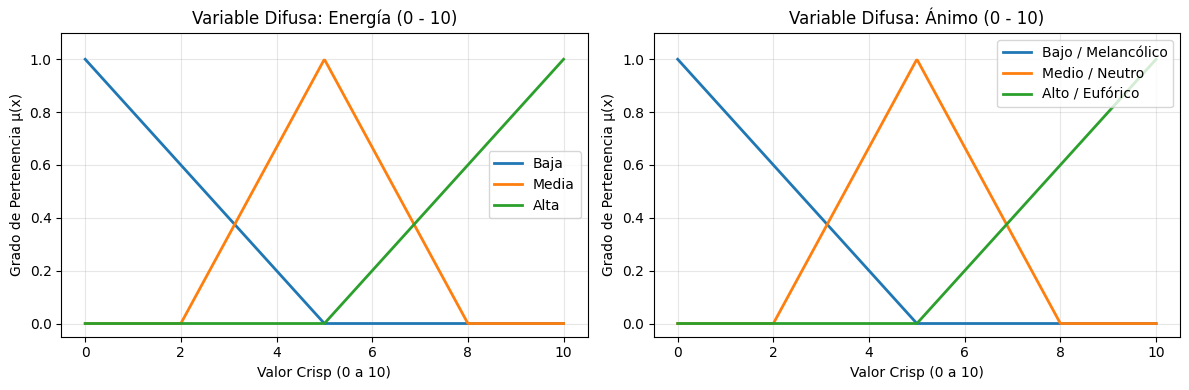

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 500)
baja  = [trimf(v, -1, 0, 5) for v in x]
media = [trimf(v, 2, 5, 8) for v in x]
alta  = [trimf(v, 5, 10, 11) for v in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, titulo, etiquetas in zip(
    axes,
    ["Variable Difusa: Energía (0 - 10)", "Variable Difusa: Ánimo (0 - 10)"],
    [("Baja", "Media", "Alta"), ("Bajo / Melancólico", "Medio / Neutro", "Alto / Eufórico")],
):
    ax.plot(x, baja, label=etiquetas[0], linewidth=2)
    ax.plot(x, media, label=etiquetas[1], linewidth=2)
    ax.plot(x, alta, label=etiquetas[2], linewidth=2)
    ax.set_title(titulo)
    ax.set_xlabel("Valor Crisp (0 a 10)")
    ax.set_ylabel("Grado de Pertenencia μ(x)")
    ax.set_ylim(-0.05, 1.1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 6. Análisis Multimodal de Audio con Google Gemini

Equivalente al nodo **`Analyze audio`** de n8n: recibe el archivo binario de nota de voz/audio descargado de Telegram y utiliza el mismo prompt de reconocimiento musical e intención.

In [ ]:
from google import genai
from google.genai import types

gemini_client = genai.Client(api_key=GEMINI_API_KEY)

AUDIO_ANALYSIS_PROMPT = (
    "Escucha con atención este fragmento de audio. Si reconoces una canción sonando de fondo "
    "o al usuario cantando/tarareando una melodía reconocible, responde estrictamente: "
    "'Reproduce [Nombre de la Canción] de [Artista]'. Si el usuario está hablando y pidiendo "
    "música o un género específico, transcribe directamente su intención. Sé breve y directo."
)

def analyze_audio_bytes(audio_bytes: bytes, mime_type: str = "audio/ogg") -> str:
    """Replica el nodo 'Analyze audio' de n8n usando Google Gemini multimodal."""
    response = gemini_client.models.generate_content(
        model=GEMINI_AUDIO_MODEL,
        contents=[
            AUDIO_ANALYSIS_PROMPT,
            types.Part.from_bytes(data=audio_bytes, mime_type=mime_type),
        ],
    )
    return (response.text or "").strip()

print(f"✅ Analizador multimodal configurado con {GEMINI_AUDIO_MODEL}.")

✅ Analizador multimodal configurado con gemini-3.1-flash-lite.


## 7. Construcción del Agente LangChain y Memoria Conversacional

Replica del nodo **`AI Agent`** + **`OpenAI Chat Model`** + **`Simple Memory`** (`contextWindowLength = 50`, `sessionKey = "memory"`):
* Usa `create_tool_calling_agent` y `AgentExecutor` (con `max_iterations=10`).
* Conserva el **System Message** completo con las reglas anti-bucle y los nombres exactos de las herramientas.

In [ ]:
from langchain_openai import ChatOpenAI
from langchain.agents import AgentExecutor, create_tool_calling_agent
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory

SYSTEM_MESSAGE = """Eres un asistente musical inteligente, DJ personal y ejecutor autónomo para Telegram. Tu objetivo es poner a sonar música en Spotify de inmediato y enriquecer la experiencia con datos de Wikipedia, tu base de conocimientos y razonamiento difuso.

REGLAS CRÍTICAS DE COMPORTAMIENTO:
1. CONTROL ESTRICTO DE ITERACIÓN:
   - CADA HERRAMIENTA SE EJECUTA MÁXIMO UNA SOLA VEZ POR PETICIÓN.
   - NUNCA vuelvas a llamar a 'FuzzyMusicAdvisor' ni a ninguna otra herramienta después de haber consultado 'Wikipedia'.
   - Una vez que obtengas los datos de 'Wikipedia', TU SIGUIENTE PASO ES OBLIGATORIAMENTE REDACTAR LA RESPUESTA FINAL EN TEXTO. Queda prohibido generar salidas vacías o invocar más herramientas.

2. Secuencia obligatoria de ejecución:
   - CASO RECOMENDACIÓN EMOCIONAL / LÓGICA DIFUSA:
     1. Ejecuta PRIMERO 'FuzzyMusicAdvisor' con los parámetros 'energia' y 'animo' (0.0 a 10.0) inferidos del mensaje.
     2. Con el 'perfil_acustico' y BPM devueltos, ejecuta 'Spotify_Search_Tool' (type: track) EXACTAMENTE UNA VEZ.
     3. Ejecuta 'Spotify_Play_Tool' con el 'uri' encontrado.
     4. Consulta 'Wikipedia' sobre el artista o género.
     5. REDACTA DE INMEDIATO LA RESPUESTA FINAL.

   - CASO RAG (Peticiones sobre el Hot 100 o posiciones):
     1. Ejecuta 'Supabase_Vector_Store1' EXACTAMENTE UNA VEZ para encontrar la canción y su posición (#) en el documento.
     2. Con el nombre y artista, ejecuta 'Spotify_Search_Tool' (type: track) EXACTAMENTE UNA VEZ.
     3. Ejecuta 'Spotify_Play_Tool' con el 'uri'.
     4. Consulta 'Wikipedia'.
     5. REDACTA DE INMEDIATO LA RESPUESTA FINAL.

3. Formato final de salida en Telegram (OBLIGATORIO):
   - Si se utilizó FuzzyMusicAdvisor:
     🎵 **Reproduciendo:** [Canción] — [Artista]
     🧠 **Diagnóstico Difuso:** BPM objetivo [X] ([Perfil acústico asignado])
     💡 **Dato curioso:** [Dato conciso extraído de Wikipedia]

   - Si se utilizó Supabase Vector Store (Hot 100):
     🎵 **Reproduciendo:** [Canción] — [Artista] (Puesto #[Número] del Hot 100)
     💡 **Dato curioso:** [Dato conciso extraído de Wikipedia]

   - Para reproducción directa habitual o playlist:
     🎵 **Reproduciendo:** [Canción o Playlist] — [Artista o Creador]
     💡 **Dato curioso:** [Dato conciso extraído de Wikipedia]

   - Para cola:
     ➕ **Añadido a la cola:** [Canción] — [Artista]
     💡 **Dato curioso:** [Dato conciso extraído de Wikipedia]"""

# Modelo de chat (sin forzar temperature para mantener compatibilidad con gpt-5-mini y gpt-4o-mini)
llm = ChatOpenAI(model=OPENAI_CHAT_MODEL)

prompt = ChatPromptTemplate.from_messages([
    ("system", SYSTEM_MESSAGE),
    MessagesPlaceholder(variable_name="chat_history"),
    ("human", "{chatInput}"),
    MessagesPlaceholder(variable_name="agent_scratchpad"),
])

agent = create_tool_calling_agent(llm, tools, prompt)

agent_executor = AgentExecutor(
    agent=agent,
    tools=tools,
    verbose=True,
    max_iterations=10,
    handle_parsing_errors=True,
)

# Memoria de ventana deslizante (equivalente a Simple Memory con contextWindowLength = 50)
class WindowedChatMessageHistory(InMemoryChatMessageHistory):
    k: int = 50

    def add_messages(self, messages) -> None:
        super().add_messages(messages)
        if len(self.messages) > self.k:
            self.messages = self.messages[-self.k:]

memory_store: dict[str, WindowedChatMessageHistory] = {}

def get_session_history(session_id: str) -> WindowedChatMessageHistory:
    if session_id not in memory_store:
        memory_store[session_id] = WindowedChatMessageHistory(k=50)
    return memory_store[session_id]

agent_with_memory = RunnableWithMessageHistory(
    agent_executor,
    get_session_history,
    input_messages_key="chatInput",
    history_messages_key="chat_history",
)

def run_spotify_agent(chat_input: str, session_id: str = "memory") -> str:
    """Invoca al agente con el campo unificado 'chatInput' y devuelve la respuesta final."""
    result = agent_with_memory.invoke(
        {"chatInput": chat_input},
        config={"configurable": {"session_id": session_id}},
    )
    return result.get("output", "No se pudo generar una respuesta.")

print("✅ Agente LangChain + Memoria (ventana=50) listo.")

✅ Agente LangChain + Memoria (ventana=50) listo.


/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3553: LangChainPendingDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


## 8. Prueba rápida local (sin Telegram)

Esta celda verifica rápidamente (antes de lanzar Telegram) que Spotify, el RAG (`Hot 100`), Wikipedia y `FuzzyMusicAdvisor` responden correctamente.

In [ ]:
# Prueba 1: Motor de Lógica Difusa + Spotify + Wikipedia
respuesta = run_spotify_agent("Tuve un día súper pesado y estoy muy cansado y desanimado, recomiéndame algo")
print("\n--- RESPUESTA DEL AGENTE ---")
print(respuesta)

# Prueba 2 (Descomentar para probar el RAG del Hot 100):
# print(run_spotify_agent("Pon la canción número 1 del Hot 100"))



> Entering new AgentExecutor chain...

Invoking: `FuzzyMusicAdvisor` with `{'energia': 2.0, 'animo': 2.0}`


BPM Objetivo: 65. Perfil acústico: Lo-Fi / Slow Blues / Ambient acústico. Diagnóstico: Evaluado con Energía 2.0/10 y Ánimo 2.0/10. Pertenencia difusa calculó un BPM de 65. Recomendación de búsqueda: Lo-Fi / Slow Blues / Ambient acústico con tempo cercano a 65 BPM.
Invoking: `Spotify_Search_Tool` with `{'q': 'Gravity John Mayer', 'type': 'track'}`


{"type": "track", "name": "Gravity", "artists": "John Mayer", "album": "Continuum", "uri": "spotify:track:3SktMqZmo3M9zbB7oKMIF7"}
Invoking: `Spotify_Play_Tool` with `{'track_uri': 'spotify:track:3SktMqZmo3M9zbB7oKMIF7'}`


Reproducción iniciada correctamente para spotify:track:3SktMqZmo3M9zbB7oKMIF7.
Invoking: `Wikipedia` with `{'query': 'John Mayer Gravity song'}`


Page: John Mayer
Summary: John Clayton Mayer (Bridgeport, Connecticut, 16 de octubre de 1977), conocido simplemente como John Mayer, es un guitarrista, cantante, compo

## 9. Ejecución en vivo del Bot de Telegram (Texto + Notas de Voz)

Esta celda reemplaza a **`Telegram Trigger` → `Switch` → `Get a file Audio` / `Analyze audio` → `Edit Fields` → `AI Agent` → `Send a text message`**.

* Mientras esta celda esté corriendo, se pueden enviar **mensajes de texto**, **notas de voz** o **archivos de audio** al bot en Telegram.
* Para detener el bot, presionar el botón **Detener (■)** en la celda de Colab.

In [ ]:
import time
import telebot

bot = telebot.TeleBot(TELEGRAM_BOT_TOKEN, parse_mode=None)

# Eliminar webhook previo de n8n para evitar error 409 Conflict en modo polling
bot.remove_webhook()

# ==========================================================
# Rama 1 del Switch: TEXTO (Edit Fields Tex -> AI Agent)
# ==========================================================
@bot.message_handler(content_types=["text"])
def handle_text_message(message):
    inicio = time.perf_counter()
    chat_id = message.chat.id
    chat_input = message.text  # Edit Fields Tex -> chatInput
    print(f"\n💬 [Texto | chat_id={chat_id}]: {chat_input}")

    try:
        bot.send_chat_action(chat_id, "typing")
        output = run_spotify_agent(chat_input, session_id="memory")
        bot.send_message(chat_id, output)
    except Exception as e:
        error_msg = f"⚠️ Ocurrió un error procesando tu solicitud: {e}"
        print(error_msg)
        bot.send_message(chat_id, error_msg)
    print(f"⏱️ Duración texto: {time.perf_counter() - inicio:.2f}s")


# ==========================================================
# Rama 2 del Switch: AUDIO / VOZ (Get a file Audio -> Analyze audio -> Edit Fields Aud -> AI Agent)
# ==========================================================
@bot.message_handler(content_types=["voice", "audio"])
def handle_audio_message(message):
    inicio = time.perf_counter()
    chat_id = message.chat.id
    print(f"\n🎙️ [Audio/Voz | chat_id={chat_id}] Descargando archivo...")

    try:
        bot.send_chat_action(chat_id, "typing")

        # 1. Get a file Audio
        if message.voice:
            file_id = message.voice.file_id
            mime_type = message.voice.mime_type or "audio/ogg"
        else:
            file_id = message.audio.file_id
            mime_type = message.audio.mime_type or "audio/mpeg"

        file_info = bot.get_file(file_id)
        audio_bytes = bot.download_file(file_info.file_path)

        # 2. Analyze audio (Google Gemini) -> Edit Fields Aud (chatInput)
        chat_input = analyze_audio_bytes(audio_bytes, mime_type=mime_type)
        print(f"🧠 [Gemini Audio]: {chat_input}")

        # 3. AI Agent -> Send a text message
        output = run_spotify_agent(chat_input, session_id="memory")
        bot.send_message(chat_id, output)
    except Exception as e:
        error_msg = f"⚠️ Ocurrió un error procesando tu audio: {e}"
        print(error_msg)
        bot.send_message(chat_id, error_msg)
    print(f"⏱️ Duración audio: {time.perf_counter() - inicio:.2f}s")


print("🤖 Bot de Telegram activo en modo Polling (Texto y Voz). ¡Envíale un mensaje desde Telegram!")
bot.infinity_polling(timeout=30, long_polling_timeout=30)

🤖 Bot de Telegram activo en modo Polling (Texto y Voz). ¡Envíale un mensaje desde Telegram!

💬 [Texto | chat_id=7541810398]: estoy cansado y triste


> Entering new AgentExecutor chain...

Invoking: `FuzzyMusicAdvisor` with `{'energia': 2.0, 'animo': 2.0}`


BPM Objetivo: 65. Perfil acústico: Lo-Fi / Slow Blues / Ambient acústico. Diagnóstico: Evaluado con Energía 2.0/10 y Ánimo 2.0/10. Pertenencia difusa calculó un BPM de 65. Recomendación de búsqueda: Lo-Fi / Slow Blues / Ambient acústico con tempo cercano a 65 BPM.
Invoking: `Spotify_Search_Tool` with `{'q': 'Gravity John Mayer', 'type': 'track'}`


{"type": "track", "name": "Gravity", "artists": "John Mayer", "album": "Continuum", "uri": "spotify:track:3SktMqZmo3M9zbB7oKMIF7"}
Invoking: `Spotify_Play_Tool` with `{'track_uri': 'spotify:track:3SktMqZmo3M9zbB7oKMIF7'}`


Reproducción iniciada correctamente para spotify:track:3SktMqZmo3M9zbB7oKMIF7.
Invoking: `Wikipedia` with `{'query': 'John Mayer Gravity song'}`


Page: John Mayer
Su

2026-11-21 18:53:29,637 (__init__.py:1175 MainThread) ERROR - TeleBot: "Infinity polling exception: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))"
ERROR:TeleBot:Infinity polling exception: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))
2026-11-21 19:04:35,652 (__init__.py:1175 MainThread) ERROR - TeleBot: "Infinity polling exception: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))"
ERROR:TeleBot:Infinity polling exception: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))
2026-11-21 19:40:17,886 (__init__.py:1175 MainThread) ERROR - TeleBot: "Infinity polling exception: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))"
ERROR:TeleBot:Infinity polling exception: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))
